# Tarea Computacional · IMT2220 Cálculo para Ciencia de Datos (2026-2)
## Problema 2: Red neuronal con dos capas ocultas

**Grupo:** 10

**Integrantes:**
- Lucas Martín Chicao Carmona
- Ignacio Andrés Osorio Orellana
- Martín Ignacio Serrano Pizarro
- Martin Antonio Von Gehr Campos

---

**Antes de entregar**
- Ejecuten todas las celdas en orden, de principio a fin (*Reiniciar kernel y ejecutar todo*), y revisen que no haya errores.
- Solo pueden usar operaciones básicas de `numpy`, funciones para leer los datos y `matplotlib` (ver *Indicaciones para el código* en el enunciado). 
- Los desarrollos y las respuestas van en el informe (PDF). Aquí basta con el código, sus resultados y comentarios breves.
- Para obtener el PDF: en VS Code, menú `···` de la barra superior del notebook → *Exportar* → *HTML*; luego abran el `.html` en el navegador e imprímanlo como PDF.

Reemplacen cada celda marcada con `# TODO` por su código. Pueden agregar todas las celdas que necesiten.

## Configuración

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

FIGURAS = "../informe/figuras"   # el informe toma las figuras directamente desde aquí
os.makedirs(FIGURAS, exist_ok=True)

rng = np.random.default_rng(10)   # semilla fija: mismos resultados en cada ejecución

## Datos

Los archivos `datos_P2.csv` (partes (c) a (f)) y `datos_P2_g.csv` (parte (g)) deben estar en la misma carpeta que este notebook. Tienen una línea de encabezado `x,y` y dos columnas separadas por comas.

N = 200 datos;  x en [-0.990, 0.966],  y en [-0.077, 2.216]


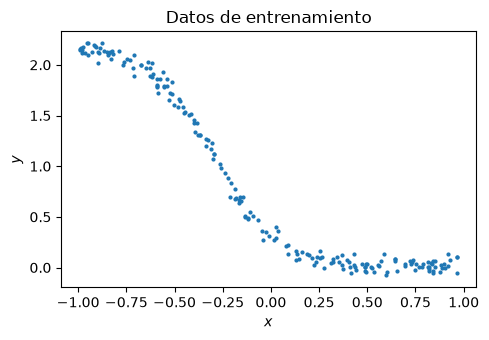

In [2]:
x, y = np.loadtxt("datos_P2.csv", delimiter=",", skiprows=1, unpack=True)
x_g, y_g = np.loadtxt("datos_P2_g.csv", delimiter=",", skiprows=1, unpack=True)
N = len(x)
print(f"N = {N} datos;  x en [{x.min():.3f}, {x.max():.3f}],  y en [{y.min():.3f}, {y.max():.3f}]")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, y, ".", ms=4)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Datos de entrenamiento")
fig.tight_layout()
fig.savefig(f"{FIGURAS}/datos_P2.png", dpi=200)
plt.show()

## Notación

Los parámetros se agrupan, en este orden, en el vector $\theta = (a_1, b_1, a_2, b_2, v, c) \in \mathbb{R}^6$.

## (a) y (b)

## (c) Implementación y verificación del gradiente

In [3]:
# TODO: programar estas funciones, con theta = (a1, b1, a2, b2, v, c).

def sigmoide(t):
    return 1.0 / (1.0 + np.exp(-t))

def d_sigmoide(t):
    return sigmoide(t) * (1 - sigmoide(t))

def predecir(theta, x):
    """Salida de la red, y_hat(x; theta)."""
    a1, b1, a2, b2, v, c = theta
    z1 = a1 * x + b1
    h1 = sigmoide(z1)
    z2 = a2 * h1 + b2
    h2 = sigmoide(z2)
    return c + v * h2


def J(theta, x, y):
    """Función de pérdida J(theta)."""
    y_hat = predecir(theta, x)
    return np.sum((y_hat - y)**2) / (2 * N)



def grad_J(theta, x, y):
    """Gradiente de J en theta, según las fórmulas de (b): arreglo de largo 6."""
    a1, b1, a2, b2, v, c = theta
    N = len(x)
    z1 = a1 * x + b1
    h1 = sigmoide(z1)
    z2 = a2 * h1 + b2
    h2 = sigmoide(z2)
    y_hat = c + v * h2
    e = y_hat - y

    dJ_dc = np.sum(e) / N
    dJ_dv = np.sum(e * h2) / N
    dJ_da2 = np.sum(e * v * d_sigmoide(z2) * h1)  / N
    dJ_db2 = np.sum(e * v * d_sigmoide(z2)) / N
    dJ_da1 = np.sum(e * v * d_sigmoide(z2) * a2 * d_sigmoide(z1) * x) / N
    dJ_db1 = np.sum(e * v * d_sigmoide(z2) * a2 * d_sigmoide(z1)) / N

    return np.array([dJ_da1, dJ_db1, dJ_da2, dJ_db2, dJ_dv, dJ_dc])

In [4]:
# TODO
theta0 = rng.uniform(-1, 1, 6)
print("theta0 =", theta0)
print(f"J(theta0) = {J(theta0, x, y):.6f}")

h = 10**-5
gradiente = grad_J(theta0, x, y)
D_j = np.zeros(6)
for j in range(6):
    theta_suma, theta_resta = theta0.copy(), theta0.copy()
    theta_suma[j] += h
    theta_resta[j] -= h
    D_j[j] = (J(theta_suma, x, y) - J(theta_resta, x, y)) / (2 * h)

E = np.max(np.abs(gradiente - D_j))
print(f"Error máximo E = {E}")

theta0 = [ 0.91200342 -0.58463638  0.65688977 -0.70143575  0.02560923 -0.72816079]
J(theta0) = 1.622869
Error máximo E = 1.740374511172149e-11


## (d) Descenso del gradiente

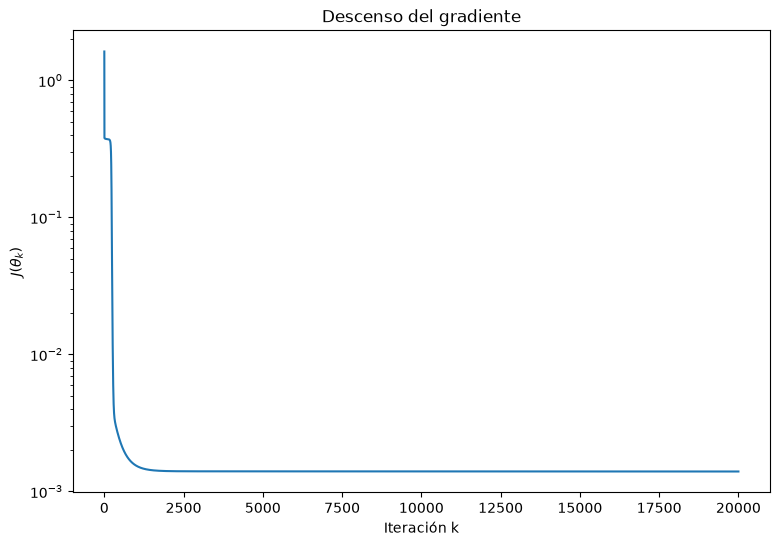

In [10]:
# TODO: programar el descenso del gradiente con paso fijo.

def descenso_gradiente(theta0, x, y, alpha, iteraciones=20_000):
    """Devuelve theta final y los valores J(theta_k) de cada iteración."""
    theta = theta0.copy()
    valores = np.zeros(iteraciones + 1)
    valores[0] = J(theta, x, y)
    for k in range(iteraciones):
        theta = theta - alpha * grad_J(theta, x, y)
        valores[k + 1] = J(theta, x, y)
    return theta, valores


# TODO
# - Ejecutarlo desde theta0 con alpha = 1 y 20.000 iteraciones.
# - Graficar J(theta_k) en función de k y guardar en f"{FIGURAS}/P2_d_error.png"
theta_grafico, valores = descenso_gradiente(theta0, x, y, alpha=1, iteraciones=20000)
fig, ax = plt.subplots(figsize=(9,6))
ax.plot(valores)
ax.set_xlabel("Iteración k")
ax.set_ylabel("$J(\\theta_k)$")
ax.set_yscale("log")
ax.set_title("Descenso del gradiente")
fig.savefig(f"{FIGURAS}/P2_d_error.png")
plt.show()

## (e) Parámetros encontrados

Datos theta_20000 (forma [a1, b1, a2, b2, v, c]):
[ 4.62336208  0.71831521  4.39355706 -0.99011768 -3.17818018  3.08573878]
J(theta_20000) = 0.0013953625538601921


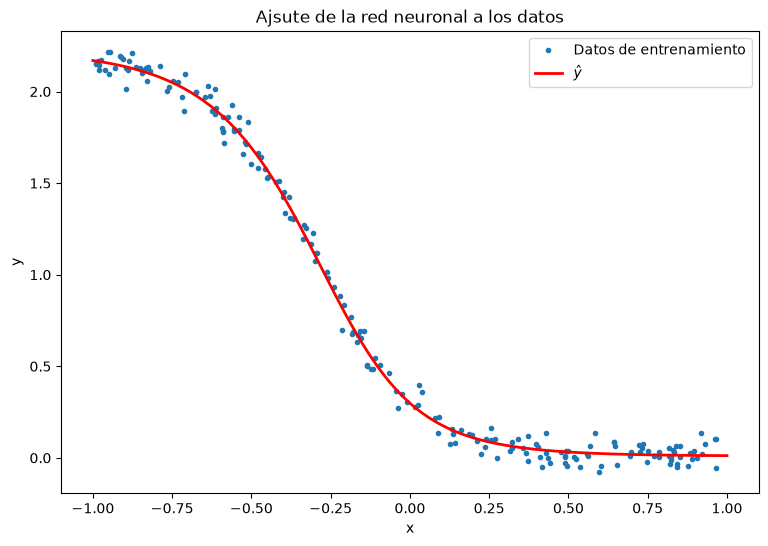

In [44]:
# TODO
# - Reportar theta_20000 y J(theta_20000).
# - Graficar los datos y la curva y_hat en [-1, 1] y guardar en f"{FIGURAS}/P2_e_ajuste.png"
print("Datos theta_20000 (forma [a1, b1, a2, b2, v, c]):")
print(theta_grafico)
print(f"J(theta_20000) = {J(theta_grafico, x, y)}")

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(x, y, ".", label="Datos de entrenamiento")
x_curva = np.linspace(-1, 1, 300)
y_hat_curva = predecir(theta_grafico, x_curva)
ax.plot(x_curva, y_hat_curva, "r-", lw=2, label=r"$\hat{y}$")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Ajsute de la red neuronal a los datos")
ax.legend()
fig.savefig(f"{FIGURAS}/P2_e_ajuste.png")
plt.show()


## (f) Sensibilidad del entrenamiento

### i. Tamaño del paso

In [7]:
# TODO
# - Repetir (d) desde el mismo theta0 con alpha en {0.01, 0.1, 1, 2.5}.
# - Graficar las cuatro curvas de error juntas y guardar en f"{FIGURAS}/P2_f_pasos.png"

### ii. Distintas inicializaciones

In [8]:
# TODO
# - Repetir (d) con alpha = 1 para 10 inicializaciones en [-1, 1] y 10 en [-5, 5].
# - Reportar el valor final de J de cada una y guardar el gráfico en f"{FIGURAS}/P2_f_inicializaciones.png"

## (g) Datos de otra función

### i. Entrenamiento con `datos_P2_g.csv`

In [9]:
# TODO
# - Entrenar con (x_g, y_g), desde el mismo theta0 de (c), con alpha = 1 y 20.000 iteraciones.
# - Graficar los datos y la curva obtenida y guardar en f"{FIGURAS}/P2_g_ajuste.png"

### ii.